In [ ]:
import json, os
import numpy as np
import pandas as pda
import matplotlib.pyplot as plt
from scipy import stats
import sys; sys.path.append("..")
from scenarios import TRAIN_FRAC

os.makedirs("../outputs/figures", exist_ok=True)

s = pd.read_csv("../data/processed/salon_clean.csv", parse_dates=["appt_dt", "booked_dt"])
sv = s[s["hour_valid"]].copy()
sv["appt_hour"] = sv["appt_hour"].astype(int)

HOURS = list(range(9, 18))
WEEKS = list(range(int(s["week_index"].max()) + 1))
n_train = int(round(len(WEEKS) * TRAIN_FRAC))
train_weeks, test_weeks = WEEKS[:n_train], WEEKS[n_train:]
print("Weeks:", len(WEEKS), "| train:", len(train_weeks), "| holdout:", len(test_weeks))

# Weeks x hours grid and empty slots kept 0
grid = (sv.groupby(["week_index", "appt_hour"]).size()
          .unstack(fill_value=0)
          .reindex(index=WEEKS, columns=HOURS, fill_value=0))
print(grid.loc[train_weeks].sum())

Weeks: 44 | train: 31 | holdout: 13
appt_hour
9     24
10    18
11    16
12    20
13    12
14    15
15    12
16    16
17    11
dtype: int64


In [2]:
# C1: tiers from training weeks only - top third = peak, bottom third = off
train_tot = grid.loc[train_weeks].sum().sort_values(ascending=False, kind="stable")
peak_hours = sorted(train_tot.index[:3])
off_hours  = sorted(train_tot.index[-3:])
TIER = {h: "peak" if h in peak_hours else "off" if h in off_hours else "mid" for h in HOURS}

print("Peak:", peak_hours, "| Off:", off_hours)
print(pd.Series(TIER).to_string())

# Saved so notebooks 05-07 use the exact same tiers
os.makedirs("../outputs/tables", exist_ok=True)
with open("../outputs/tables/tiers.json", "w") as f:
    json.dump({str(h): t for h, t in TIER.items()}, f, indent=2)

Peak: [9, 10, 12] | Off: [13, 15, 17]
9     peak
10    peak
11     mid
12    peak
13     off
14     mid
15     off
16     mid
17     off


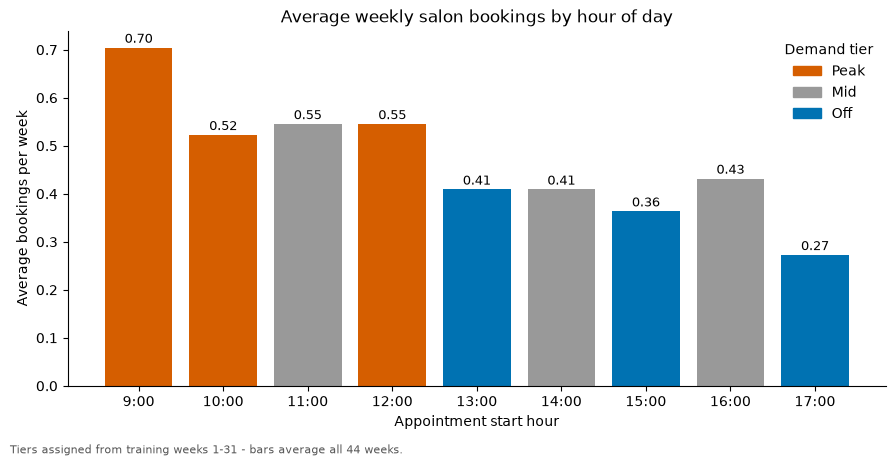

In [3]:
TIER_COLORS = {"peak": "#D55E00", "mid": "#999999", "off": "#0072B2"}   # color-blind safe
avg = grid.mean()   # avg weekly bookings per hour - all 44 weeks

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([f"{h}:00" for h in HOURS], avg, color=[TIER_COLORS[TIER[h]] for h in HOURS])
for b, v in zip(bars, avg):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=t.title()) for t, c in TIER_COLORS.items()],
          title="Demand tier", frameon=False)
ax.set(title="Average weekly salon bookings by hour of day",
       xlabel="Appointment start hour", ylabel="Average bookings per week")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Tiers assigned from training weeks 1-31 - bars average all 44 weeks.",
         fontsize=8, color="#555555")
fig.tight_layout()
fig.savefig("../outputs/figures/fig01_hour_demand.png", dpi=200)
plt.show()

In [4]:
# Kruskal-Wallis - do weekly booking counts differ by hour of day?
# Each group = one hours weekly counts (44 values each)
kw = stats.kruskal(*[grid[h] for h in HOURS])
n_obs = grid.size
eps2 = (kw.statistic - len(HOURS) + 1) / (n_obs - len(HOURS))   # effect size
print(f"Kruskal-Wallis by hour: H = {kw.statistic:.2f}, p = {kw.pvalue:.4f}, epsilon^2 = {eps2:.3f}")

# Chi-square goodness of fit: are weekday counts even?
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
obs = s["appt_dt"].dt.day_name().value_counts().reindex(order)
chi = stats.chisquare(obs)
print(obs.to_string())
print(f"Chi-square weekday: chi2 = {chi.statistic:.2f}, p = {chi.pvalue:.4f}")

Kruskal-Wallis by hour: H = 12.23, p = 0.1412, epsilon^2 = 0.011
appt_dt
Monday       22
Tuesday      16
Wednesday    34
Thursday     31
Friday       25
Saturday     33
Sunday       25
Chi-square weekday: chi2 = 9.55, p = 0.1450


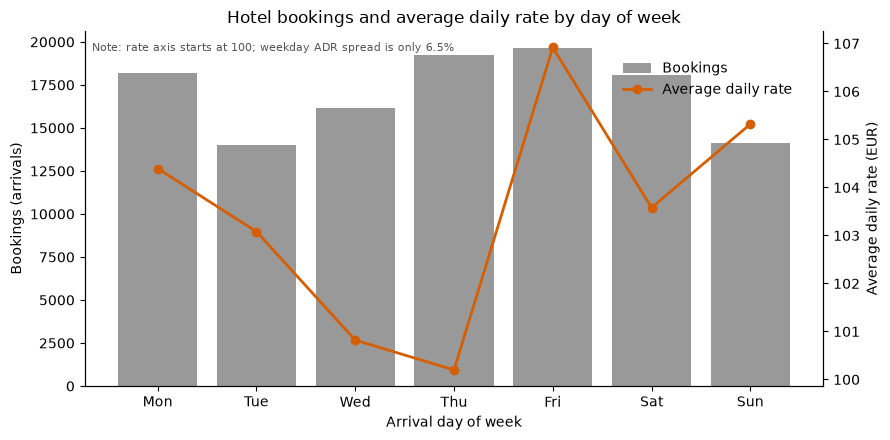

weekday
Monday       18171
Tuesday      13999
Wednesday    16139
Thursday     19254
Friday       19631
Saturday     18055
Sunday       14141
weekday
Monday       104.39
Tuesday      103.08
Wednesday    100.82
Thursday     100.20
Friday       106.92
Saturday     103.58
Sunday       105.32
ADR spread (max-min)/mean: 6.5%
Kruskal-Wallis ADR by weekday: H = 424.1, p = 1.82e-88, epsilon^2 = 0.0036


In [5]:
h = pd.read_csv("../data/processed/hotel_clean.csv", parse_dates=["arrival_date"])
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

cnt = h["weekday"].value_counts().reindex(order)
hv = h[h["adr_valid"]]
adr = hv.groupby("weekday")["adr"].mean().reindex(order)
spread = (adr.max() - adr.min()) / adr.mean()          # <-- moved up: needed by the chart note

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar([d[:3] for d in order], cnt, color="#999999", label="Bookings")
ax.set(ylabel="Bookings (arrivals)", xlabel="Arrival day of week",
       title="Hotel bookings and average daily rate by day of week")
ax2 = ax.twinx()
ax2.plot([d[:3] for d in order], adr, color="#D55E00", marker="o", lw=2, label="Average daily rate")
ax2.set_ylabel("Average daily rate (EUR)")
for ax_ in (ax, ax2): ax_.spines[["top"]].set_visible(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88), frameon=False)
ax2.text(0.01, 0.97, f"Note: rate axis starts at {ax2.get_ylim()[0]:.0f}; "
         f"weekday ADR spread is only {spread:.1%}",
         transform=ax2.transAxes, fontsize=8, color="#555555", va="top")
fig.tight_layout()
fig.savefig("../outputs/figures/fig02_hotel_dow.png", dpi=200)
plt.show()

print(cnt.to_string()); print(adr.round(2).to_string())
print(f"ADR spread (max-min)/mean: {spread:.1%}")

kw_adr = stats.kruskal(*[g["adr"] for _, g in hv.groupby("weekday")])
eps2_adr = (kw_adr.statistic - 7 + 1) / (len(hv) - 7)
print(f"Kruskal-Wallis ADR by weekday: H = {kw_adr.statistic:.1f}, p = {kw_adr.pvalue:.2e}, epsilon^2 = {eps2_adr:.4f}")

      bookings  median_lead  cancel_rate
tier                                    
peak        78         20.5        0.115
mid         61         16.0        0.148
off         46          8.0        0.130
Kruskal-Wallis lead time by tier: H = 6.45, p = 0.0397

Salon cancel/no-show: 13.4% | Hotel: 37.0%
Salon median lead: 14.5 days | Hotel: 69 days


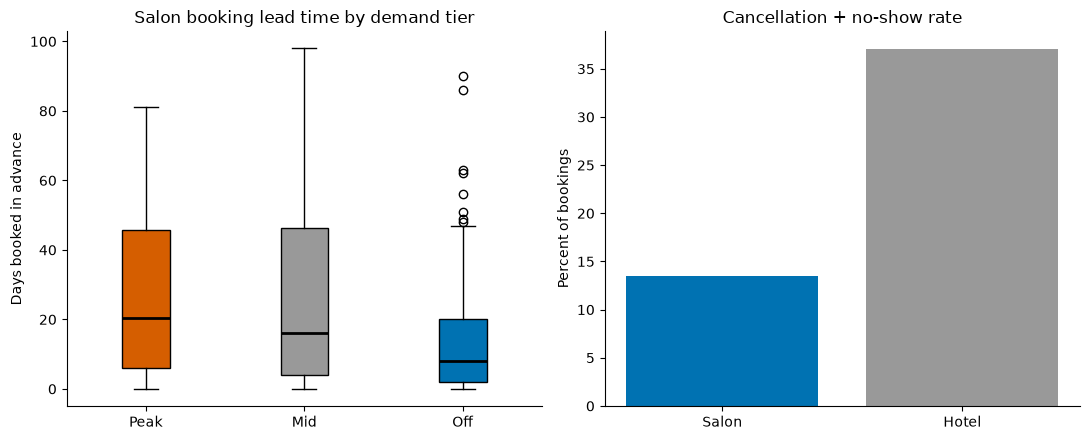

In [6]:
sv["tier"] = sv["appt_hour"].map(TIER)
by_tier = (sv.groupby("tier")
             .agg(bookings=("tier", "size"),
                  median_lead=("lead_days", "median"),
                  cancel_rate=("cancel_or_noshow", "mean"))
             .reindex(["peak", "mid", "off"]))
print(by_tier.round(3))

kw_lead = stats.kruskal(*[sv.loc[sv.tier == t, "lead_days"].dropna() for t in ["peak", "mid", "off"]])
print(f"Kruskal-Wallis lead time by tier: H = {kw_lead.statistic:.2f}, p = {kw_lead.pvalue:.4f}")

# Hotel benchmark for comparison
print(f"\nSalon cancel/no-show: {s['cancel_or_noshow'].mean():.1%} | Hotel: {h['cancel_or_noshow'].mean():.1%}")
print(f"Salon median lead: {s['lead_days'].median():.1f} days | Hotel: {h['lead_time'].median():.0f} days")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
data = [sv.loc[sv.tier == t, "lead_days"].dropna() for t in ["peak", "mid", "off"]]
bp = axes[0].boxplot(data, tick_labels=["Peak", "Mid", "Off"], patch_artist=True,
                     medianprops=dict(color="black", linewidth=2))
for patch, t in zip(bp["boxes"], ["peak", "mid", "off"]):
    patch.set_facecolor(TIER_COLORS[t])
axes[0].set(title="Salon booking lead time by demand tier", ylabel="Days booked in advance")
axes[1].bar(["Salon", "Hotel"], [s["cancel_or_noshow"].mean()*100, h["cancel_or_noshow"].mean()*100],
            color=["#0072B2", "#999999"])
axes[1].set(title="Cancellation + no-show rate", ylabel="Percent of bookings")
for ax_ in axes: ax_.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../outputs/figures/fig03_lead_cancel.png", dpi=200)
plt.show()

## Insights and Finds
- Tiers / training weeks: peak 9, 10, 12 | mid 11, 14, 16 | off 13, 15, 17

- Booking volume by hour: not significant (Kruskal-Wallis p = 0.141)

- Lead time by tier: significant (p = 0.040); peak 20.5 vs off-peak 8 days

- Salon weekday counts consistent with even spread (chi-square p = 0.145), as expected from the date shift

- Hotel weekday ADR spread 6.5%: revenue-managed rates vary modestly by weekday

- Cancel / no-show: salon 13.4% vs hotel 37.0%